# Rôle 2 : analyse non supervisée des 2 000 projets

Ce notebook suit les tâches du rôle 2 (`docs/plan-role2.md`) :

1. **préparation des données** (ce qui suit) ;
2. ACP ;
3. clustering (K-means, hiérarchique, DBSCAN, mélange gaussien).

Le fichier `anomalies_injectees.csv` (vérité terrain) n'est **pas** lu ici : l'analyse non supervisée n'utilise aucune étiquette.

## Tâche 1 : préparation des données

### Choix des variables

`projets.csv` n'a que trois colonnes chiffrées réelles : le coût, la durée et l'année d'approbation. Pour que les groupes parlent la langue du classement, on ajoute les cinq critères que l'agent calcule pour chaque projet :

- `rentabilite_predite` et `proba_risque`, donnés par `predict` (rôle 1) ;
- `impact_env_social`, `alignement_strategique` et `faisabilite`, notes de 1 à 5 données par `extract` (rôle 3) à partir du document du projet.

Soit **8 variables**. Le secteur, la région et le type de financement ne servent qu'à **décrire** les groupes ensuite, pas à les former.

À garder en tête :

- **Exclues** : les cibles `rentabilite` et `risque`. Elles sont vides pour les 500 projets en cours et simulées par une formule.
- **Redondance** : la rentabilité et le risque prédits sont calculés par le rôle 1 à partir du coût, de la durée, de l'année, du secteur et du pays. Ils sont donc en partie redondants avec les trois chiffres, et l'ACP le montrera.
- **Projets déjà vus** : pour les 1 500 projets terminés, ces prédictions portent sur des projets vus pendant l'apprentissage du rôle 1. Elles collent donc mieux aux vraies valeurs que pour un projet nouveau. Cela ne gêne pas une analyse descriptive comme celle-ci, qui ne mesure aucune performance de prédiction.
- **Anomalies gardées** : les 40 anomalies fabriquées restent dans les données. Une analyse non supervisée ne sait pas lesquelles sont fausses : elles apparaîtront comme des points isolés.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

RACINE = Path.cwd().resolve().parents[1]  # le notebook s'exécute depuis notebooks/role2
sys.path.insert(0, str(RACINE))
logging.basicConfig(level=logging.WARNING)

from src.nlp import extract
from src.supervise import predict

FIGURES = RACINE / "reports" / "role2" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
GRAINE = 42

In [2]:
projets = pd.read_csv(RACINE / "data" / "processed" / "projets.csv")
colonnes_fiche = ["id_projet", "nom", "secteur", "pays", "region", "cout_total", "duree_mois",
                  "annee_approbation", "type_financement"]
NOTES = ["impact_env_social", "alignement_strategique", "faisabilite"]

lignes = []
for fiche in projets[colonnes_fiche].to_dict("records"):  # fiche sans les cibles, comme pour l'agent
    prediction = predict(fiche)
    notes = extract((RACINE / "data" / "docs" / f"{fiche['id_projet']}.txt").read_text(encoding="utf-8"))
    lignes.append({"id_projet": fiche["id_projet"],
                   "rentabilite_predite": prediction["rentabilite_predite"],
                   "proba_risque": prediction["proba_risque"],
                   **{c: notes[c] for c in NOTES}})
donnees = projets.merge(pd.DataFrame(lignes), on="id_projet")
print(donnees.shape)
donnees.head(3)

(2000, 17)


,id_projet,nom,secteur,pays,region,cout_total,duree_mois,annee_approbation,type_financement,statut,rentabilite,risque,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite
0,P000001,West Africa Pilot Community-based Natural Reso...,Gouvernance,Africa,Afrique,13.19,106,1995,Autre,termine,5.5,eleve,4.81,0.355200,4,3,3
1,P000034,INFRASTRUCTURE REHAB,Transport,Angola,Afrique de l'Est et australe,23.20,92,1991,IDA,termine,6.9,faible,7.48,0.067053,2,1,2
2,P000044,Financial Institutions modernization project,Finance,Angola,Afrique de l'Est et australe,21.00,116,1992,IDA,termine,4.1,moyen,5.50,0.464793,3,3,4


### Valeurs manquantes

Seules les cibles sont vides (les 500 projets en cours). Elles ne servent pas ici. Les 8 variables retenues sont complètes : il n'y a rien à remplacer.

In [3]:
VARIABLES_BRUTES = ["cout_total", "duree_mois", "annee_approbation", "rentabilite_predite",
                    "proba_risque", *NOTES]
print(donnees.isna().sum()[lambda s: s > 0].to_string())
print("Manquants dans les 8 variables :", int(donnees[VARIABLES_BRUTES].isna().sum().sum()))

rentabilite    500
risque         500
Manquants dans les 8 variables : 0


### Asymétrie et log du coût

Le coût va de 1 à près de 38 000 millions de dollars. Quelques projets géants écraseraient tous les autres dans une méthode fondée sur des distances. Le log10 rend la distribution à peu près symétrique : un projet de 10 M$ et un de 100 M$ sont alors aussi éloignés qu'un de 100 M$ et un de 1 000 M$.

In [4]:
asymetrie = donnees[VARIABLES_BRUTES].skew().rename("asymétrie").to_frame()
donnees["log_cout"] = np.log10(donnees["cout_total"])
asymetrie.loc["log_cout (log10 du coût)"] = donnees["log_cout"].skew()
asymetrie.round(2)

,asymétrie
cout_total,18.52
duree_mois,0.10
annee_approbation,-0.42
rentabilite_predite,0.14
proba_risque,1.12
impact_env_social,-0.79
alignement_strategique,-0.98
faisabilite,-0.65
log_cout (log10 du coût),0.06


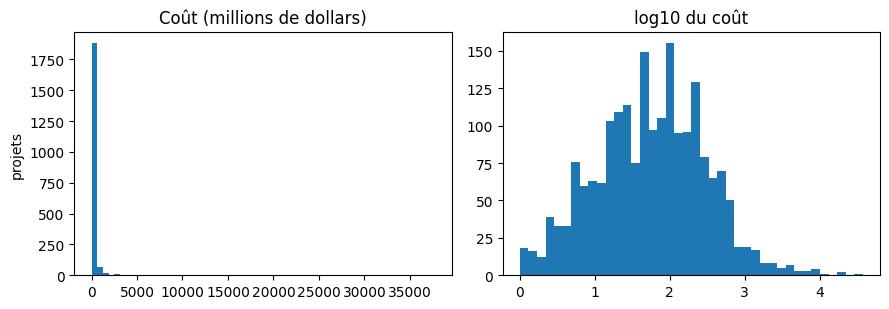

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(donnees["cout_total"], bins=60, color="tab:blue")
axes[0].set_title("Coût (millions de dollars)")
axes[0].set_ylabel("projets")
axes[1].hist(donnees["log_cout"], bins=40, color="tab:blue")
axes[1].set_title("log10 du coût")
fig.tight_layout()
fig.savefig(FIGURES / "cout_avant_apres_log.png", dpi=150)
plt.show()

Les autres variables gardent leur échelle : la durée et l'année sont à peu près symétriques. La probabilité de risque et les notes sont asymétriques, mais bornées : il n'y a pas de valeur géante à écraser.

### Liens entre variables

On s'attend à ce que la rentabilité et le risque prédits soient liés au coût et à la durée, puisque le rôle 1 les calcule à partir d'eux.

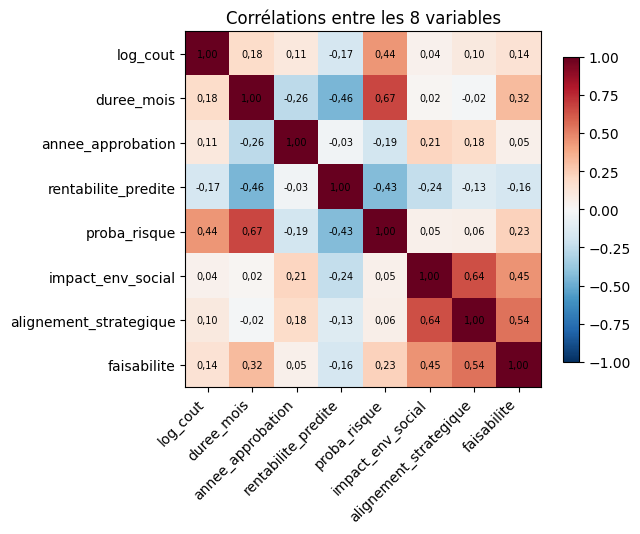

In [6]:
VARIABLES = ["log_cout", "duree_mois", "annee_approbation", "rentabilite_predite", "proba_risque", *NOTES]
correlations = donnees[VARIABLES].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=45, ha="right")
ax.set_yticks(range(len(VARIABLES)), VARIABLES)
for i in range(len(VARIABLES)):
    for j in range(len(VARIABLES)):
        ax.text(j, i, f"{correlations.iat[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Corrélations entre les 8 variables")
fig.tight_layout()
fig.savefig(FIGURES / "correlations_variables.png", dpi=150)
plt.show()

### Standardisation

L'ACP, K-means, la classification hiérarchique et DBSCAN mesurent des distances. Sans mise à l'échelle, l'année (de 1987 à 2026) pèserait des centaines de fois plus que la probabilité de risque (de 0 à 1). `StandardScaler` centre chaque variable (moyenne 0) et la réduit (écart-type 1) : chacune compte autant.

In [7]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(donnees[VARIABLES]), columns=VARIABLES, index=donnees["id_projet"])
X.describe().loc[["mean", "std", "min", "max"]].round(2)

,log_cout,duree_mois,annee_approbation,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite
mean,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.39,-2.10,-2.40,-3.29,-0.94,-2.82,-3.42,-3.12
max,3.87,3.46,1.46,3.47,2.66,1.02,1.20,0.90


In [8]:
# Points extrêmes après standardisation (à plus de 4 écarts-types sur au moins une variable)
extremes = (X.abs() > 4).any(axis=1)
print(f"{int(extremes.sum())} projets à plus de 4 écarts-types sur au moins une variable")
print((X.abs() > 4).sum()[lambda s: s > 0].to_string())

0 projets à plus de 4 écarts-types sur au moins une variable
Series([], )


### Bilan de la préparation

- **Table d'analyse** : 2 000 projets, 8 variables standardisées (`X`) : log10 du coût, durée, année, rentabilité prédite, probabilité de risque, et les trois notes qualitatives. Aucune valeur manquante. Le secteur, la région et le type de financement restent à côté, pour décrire les groupes.
- **Log du coût** : l'asymétrie passe de 18,5 à 0,06.
- **Deux blocs de variables liées** :
  - **chiffres et prédictions** : la probabilité de risque suit la durée (corrélation 0,67) et le coût (0,44) ; la rentabilité prédite baisse avec la durée (−0,46). C'est la redondance attendue, puisque le rôle 1 calcule ces prédictions à partir du coût et de la durée ;
  - **notes du texte** : impact, alignement et faisabilité sont liés entre eux (0,45 à 0,64) mais presque pas aux chiffres (moins de 0,25 en valeur absolue, sauf faisabilité et durée, 0,32).

  On peut s'attendre à ce que l'ACP retrouve ces deux blocs comme ses deux premiers axes (tâche 2).
- **Pas de point extrême après standardisation** : aucun projet n'est à plus de 4 écarts-types sur une variable. Les anomalies fabriquées ne se voient donc pas variable par variable. Un coût multiplié par 10 à 50 ajoute 1 à 1,7 au log10 (dont l'écart-type vaut 0,73), soit 1,4 à 2,3 écarts-types. C'est en combinant les variables (le coût par mois, par exemple) que l'Isolation Forest de `detect_anomalies` les repère en partie.


## Tâche 2 : analyse en composantes principales (ACP)

L'ACP cherche de nouveaux axes, combinaisons des 8 variables standardisées, qui résument le plus possible la dispersion des projets. Le premier axe est la direction où les projets sont le plus étalés, le deuxième la suivante, perpendiculaire au premier, etc. Chaque axe a une **valeur propre** : la quantité de variance qu'il résume, en « nombre de variables » (la somme des 8 valeurs propres vaut 8).

**Règle pour le nombre de composantes, fixée avant de voir le résultat** : on garde les axes de valeur propre supérieure à 1 (critère de Kaiser : un axe doit résumer plus qu'une variable à elle seule), puis on vérifie avec le coude du graphique et la part de variance cumulée.

In [9]:
from sklearn.decomposition import PCA

acp = PCA(svd_solver="full").fit(X)
valeurs_propres = acp.explained_variance_ * (len(X) - 1) / len(X)  # variance des coordonnées (somme = 8)
variance = pd.DataFrame({
    "valeur propre": valeurs_propres,
    "variance expliquée (%)": 100 * acp.explained_variance_ratio_,
    "cumulée (%)": 100 * np.cumsum(acp.explained_variance_ratio_),
}, index=[f"CP{i}" for i in range(1, len(VARIABLES) + 1)])
n_kaiser = int((valeurs_propres > 1).sum())
print(f"Axes de valeur propre > 1 (Kaiser) : {n_kaiser}")
variance.round(2)

Axes de valeur propre > 1 (Kaiser) : 3


,valeur propre,variance expliquée (%),cumulée (%)
CP1,2.60,32.45,32.45
CP2,1.93,24.18,56.63
CP3,1.06,13.31,69.94
CP4,0.85,10.60,80.54
CP5,0.58,7.31,87.85
CP6,0.40,4.96,92.81
CP7,0.33,4.16,96.96
CP8,0.24,3.04,100.00


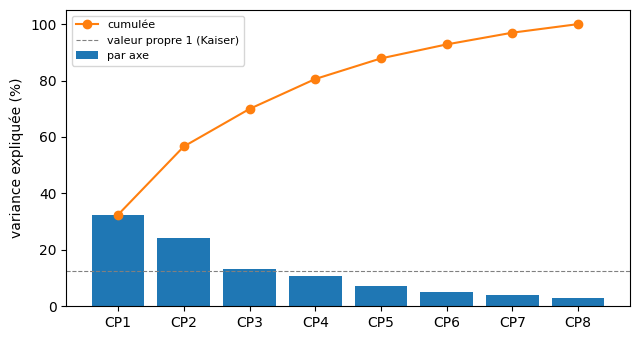

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
rangs_cp = np.arange(1, len(VARIABLES) + 1)
ax.bar(rangs_cp, variance["variance expliquée (%)"], color="tab:blue", label="par axe")
ax.plot(rangs_cp, variance["cumulée (%)"], color="tab:orange", marker="o", label="cumulée")
ax.axhline(100 / len(VARIABLES), color="grey", ls="--", lw=0.8, label="valeur propre 1 (Kaiser)")
ax.set_xticks(rangs_cp, [f"CP{i}" for i in rangs_cp])
ax.set_ylabel("variance expliquée (%)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "acp_variance.png", dpi=150)
plt.show()

### Que représente chaque axe ?

La **corrélation entre une variable et un axe** dit à quel point l'axe suit cette variable (de −1 à 1). Une variable proche de ±1 sur un axe « donne son nom » à l'axe.

In [11]:
n_axes = max(n_kaiser, 2)
saturations = pd.DataFrame(acp.components_[:n_axes].T * np.sqrt(valeurs_propres[:n_axes]),
                           index=VARIABLES, columns=[f"CP{i}" for i in range(1, n_axes + 1)])
for axe in saturations:
    fortes = saturations[axe][saturations[axe].abs() >= 0.5].sort_values(key=abs, ascending=False)
    print(axe, ":", ", ".join(f"{v} ({c:+.2f})" for v, c in fortes.items()) or "aucune corrélation >= 0,5")
saturations.round(2)

CP1 : proba_risque (+0.70), faisabilite (+0.68), duree_mois (+0.66), rentabilite_predite (-0.62), impact_env_social (+0.55), alignement_strategique (+0.55)
CP2 : alignement_strategique (+0.67), impact_env_social (+0.64), duree_mois (-0.56), annee_approbation (+0.53), proba_risque (-0.53)
CP3 : log_cout (+0.69), annee_approbation (+0.66)


,CP1,CP2,CP3
log_cout,0.44,-0.18,0.69
duree_mois,0.66,-0.56,-0.20
annee_approbation,0.01,0.53,0.66
rentabilite_predite,-0.62,0.22,-0.09
proba_risque,0.70,-0.53,0.12
impact_env_social,0.55,0.64,-0.12
alignement_strategique,0.55,0.67,-0.13
faisabilite,0.68,0.34,-0.26


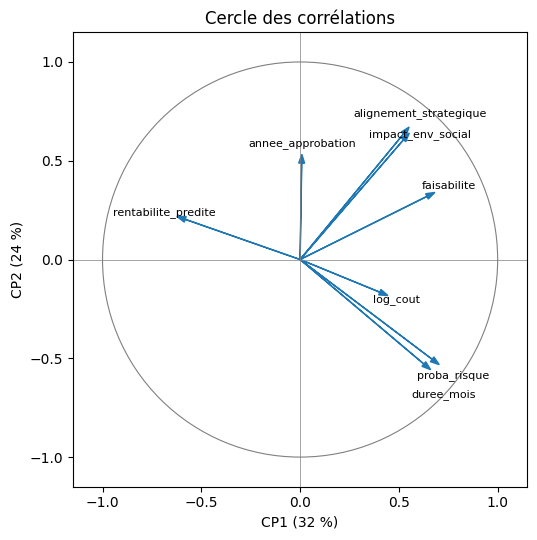

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", lw=0.8))
for variable in VARIABLES:
    x, y = saturations.loc[variable, "CP1"], saturations.loc[variable, "CP2"]
    ax.arrow(0, 0, x, y, head_width=0.03, color="tab:blue", length_includes_head=True)
    decalage = {"impact_env_social": -0.07, "duree_mois": -0.07}.get(variable, 0)  # étiquettes voisines
    ax.text(x * 1.1, y * 1.1 + decalage, variable, fontsize=8, ha="center", va="center")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal")
ax.set_xlabel(f"CP1 ({variance.iloc[0, 1]:.0f} %)")
ax.set_ylabel(f"CP2 ({variance.iloc[1, 1]:.0f} %)")
ax.set_title("Cercle des corrélations")
fig.tight_layout()
fig.savefig(FIGURES / "acp_cercle.png", dpi=150)
plt.show()

### Les projets sur les deux premiers axes

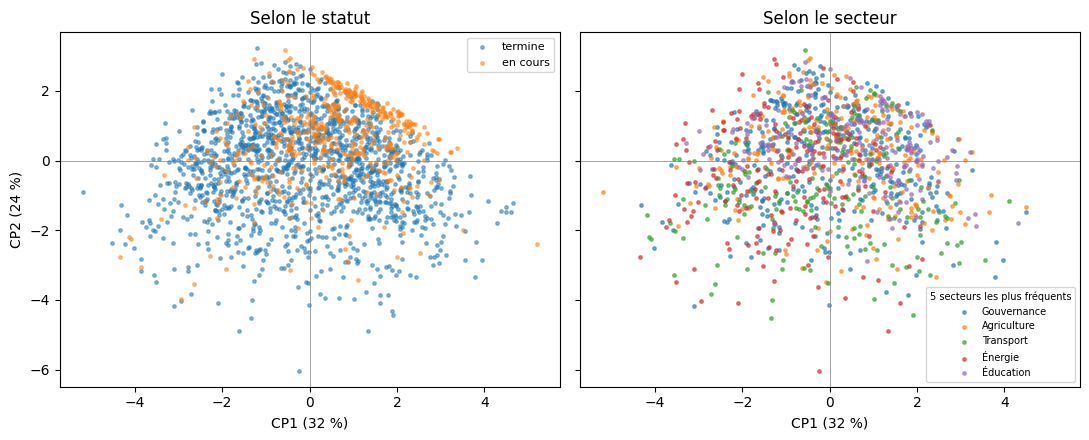

In [13]:
coordonnees = pd.DataFrame(acp.transform(X)[:, :n_axes], index=X.index,
                           columns=[f"CP{i}" for i in range(1, n_axes + 1)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for statut, couleur in [("termine", "tab:blue"), ("en_cours", "tab:orange")]:
    masque = (donnees["statut"] == statut).to_numpy()
    axes[0].scatter(coordonnees.loc[masque, "CP1"], coordonnees.loc[masque, "CP2"], s=6, alpha=0.5,
                    c=couleur, label=statut.replace("_", " "))
axes[0].legend(fontsize=8)
axes[0].set_title("Selon le statut")
secteurs = donnees["secteur"].value_counts().index[:5]
for secteur in secteurs:
    masque = (donnees["secteur"] == secteur).to_numpy()
    axes[1].scatter(coordonnees.loc[masque, "CP1"], coordonnees.loc[masque, "CP2"], s=6, alpha=0.6, label=secteur)
axes[1].legend(fontsize=7, title="5 secteurs les plus fréquents", title_fontsize=7)
axes[1].set_title("Selon le secteur")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set_xlabel(f"CP1 ({variance.iloc[0, 1]:.0f} %)")
axes[0].set_ylabel(f"CP2 ({variance.iloc[1, 1]:.0f} %)")
fig.tight_layout()
fig.savefig(FIGURES / "acp_projection.png", dpi=150)
plt.show()

In [14]:
# Position moyenne par statut et par secteur sur les axes retenus
moyennes_statut = coordonnees.groupby(donnees["statut"].to_numpy()).mean()
moyennes_secteur = coordonnees.groupby(donnees["secteur"].to_numpy()).mean().sort_values("CP1")
display(moyennes_statut.round(2))
moyennes_secteur.round(2)

,CP1,CP2,CP3
en_cours,0.44,0.62,0.85
termine,-0.15,-0.21,-0.28


,CP1,CP2,CP3
Énergie,-0.94,-0.41,0.18
Industrie et commerce,-0.65,-0.18,0.02
Finance,-0.53,-0.23,0.30
Numérique,-0.17,0.38,0.10
Gouvernance,-0.15,0.07,-0.03
Transport,-0.11,-0.73,0.25
Protection sociale,0.15,0.53,0.07
Agriculture,0.19,0.17,-0.28
Santé,0.31,0.27,0.09
Éducation,0.57,0.35,-0.17


In [15]:
# Projets les plus extrêmes sur chaque axe (pour illustrer les noms des axes)
apercu = donnees.set_index("id_projet")[["nom", "secteur", "cout_total", "duree_mois", "rentabilite_predite",
                                         "proba_risque", *NOTES]]
for axe in ["CP1", "CP2"]:
    print(f"--- {axe} : les 3 plus hauts puis les 3 plus bas")
    ids = list(coordonnees[axe].nlargest(3).index) + list(coordonnees[axe].nsmallest(3).index)
    display(apercu.loc[ids].assign(**{axe: coordonnees.loc[ids, axe].round(2)}))

--- CP1 : les 3 plus hauts puis les 3 plus bas


,nom,secteur,cout_total,duree_mois,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite,CP1
id_projet,,,,,,,,,,
P121507,Dasu Hydropower Stage I Project,Eau et assainissement,4694.75,175,1.61,0.983444,5,4,5,5.21
P145174,Health Sector Reform,Santé,338.80,147,2.32,0.967941,5,5,5,4.66
P090644,Community and Social Development Project,Protection sociale,380.00,156,3.06,0.934922,5,5,5,4.61
P049346,AGR SEC ADJ CREDIT,Agriculture,1.80,7,14.45,0.002027,2,3,1,-5.20
P009907,EXTERNAL SECTOR ADJU,Industrie et commerce,300.00,6,13.27,0.015597,2,1,2,-4.51
P002364,P.S. ADJUSTMENT & CO,Industrie et commerce,40.00,16,13.49,0.003621,2,1,3,-4.34


--- CP2 : les 3 plus hauts puis les 3 plus bas


,nom,secteur,cout_total,duree_mois,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite,CP2
id_projet,,,,,,,,,,
P175111,SPF Colombia: COVID-19 Response for Migrants f...,Protection sociale,3.25,13,12.67,0.003803,5,5,5,3.22
P512688,State of Sergipe - Phase 5 of Brazil Proactive...,Transport,135.00,2,11.64,0.009035,5,5,5,3.18
P510360,Sustainable Urban and Peri-Urban Agriculture f...,Agriculture,4.73,34,10.37,0.014542,5,5,5,2.93
P010313,PRIVATE SECTOR ENERGY DEVELOPMENT,Énergie,1522.70,125,8.00,0.903518,1,1,3,-6.03
P009869,Nathpa Jhakri Power Project,Énergie,2183.20,157,8.34,0.933601,2,3,3,-4.89
P152359,Ebola Emergency Response Project,Protection sociale,105.00,111,3.73,0.497328,1,1,1,-4.88


### Bilan de l'ACP

**Nombre de composantes : 3.** La règle fixée à l'avance (Kaiser, valeur propre supérieure à 1) garde 3 axes : 2,60, 1,93 et 1,06. Ils résument **70 %** de la variance. Le coude est moins net : la plus forte chute vient après CP2, mais CP3 apporte encore 13 % et CP4 passe sous 1 (0,85). Les deux premiers axes seuls résument 57 %.

**Nom des axes** (corrélations variable-axe d'au moins 0,5 en valeur absolue) :

| Axe | Variance | Côté positif | Côté négatif | Nom proposé |
|---|---|---|---|---|
| CP1 | 32 % | risque (+0,70), faisabilité (+0,68), durée (+0,66), impact et alignement (+0,55) | rentabilité prédite (−0,62) | **« gros programme long et bien documenté » contre « opération courte et rentable »** |
| CP2 | 24 % | alignement (+0,67), impact (+0,64), année (+0,53) | durée (−0,56), risque (−0,53) | **« projet récent, court, bien noté » contre « ancien, long, risqué »** |
| CP3 | 13 % | coût (+0,69), année (+0,66) | | **« taille et récence »** : les projets récents sont plus chers (le coût n'est pas corrigé de l'inflation) |

Les projets aux extrémités confirment ces noms. À droite de CP1, on trouve de longs programmes (147 à 175 mois) au risque prédit supérieur à 0,93 et notés 5 partout. À gauche, de vieux prêts d'ajustement (« ADJUSTMENT », 6 à 16 mois), rentables, peu risqués et mal notés : leurs documents sont courts. En bas de CP2, de grands projets d'énergie anciens et risqués, mal notés.

**Le pari de la tâche 1 n'est vrai qu'à moitié.** On attendait un axe « chiffres et prédictions » et un axe « notes du texte ». Le cercle des corrélations montre bien ces deux blocs, presque perpendiculaires : d'un côté durée et risque (en bas à droite), de l'autre impact et alignement (en haut à droite). Mais ils sont **en diagonale**, pas le long des axes. L'ACP place son premier axe entre les deux, là où la dispersion totale est la plus grande. Chaque axe mélange donc les deux blocs.

**Redondance des prédictions.** Comme prévu, le risque prédit et la durée ont presque la même flèche, et la rentabilité prédite est à l'opposé. Ces prédictions du rôle 1 apportent peu d'information nouvelle par rapport aux chiffres, puisqu'elles en sont calculées. Le coût, lui, pèse surtout sur CP3.

**Ce que montrent les projections** :

- **Statut** : les projets en cours sont plutôt en haut à droite (moyennes CP1 +0,44 ; CP2 +0,62 ; CP3 +0,85). Ils sont plus récents, plus chers et mieux notés, car leurs documents ont plus souvent un résumé.
- **Bord net en haut à droite** : ce sont les projets notés 5 sur les trois notes. Le plafond de l'échelle de 1 à 5 les aligne sur un même bord.
- **Secteur** : il ne forme pas de groupes séparés. Les secteurs se recouvrent largement, avec seulement des tendances : l'énergie à gauche de CP1 (plus rentable et moins risquée d'après le rôle 1), l'eau et l'éducation à droite, le transport en bas de CP2.

**Limites** : 70 % de la variance pour 3 axes sur 8 variables, c'est une réduction modeste. Les notes de 1 à 5 sont des variables discrètes que l'ACP traite comme continues. Les axes décrivent les projets à travers les modèles des rôles 1 et 3, pas uniquement les données réelles.


## Tâche 3 : clustering

On cherche des **groupes de projets qui se ressemblent** sur les 8 variables standardisées (`X`), sans aucune étiquette. Quatre familles de méthodes :

- **K-means** (partition) : k centres ; chaque projet va au centre le plus proche, puis chaque centre devient la moyenne de ses projets, jusqu'à stabilité. Il donne des groupes ronds, de tailles comparables.
- **Classification hiérarchique** (méthode de Ward) : on part de 2 000 groupes d'un projet et on fusionne à chaque étape les deux groupes dont la fusion augmente le moins la dispersion. Le dendrogramme garde la trace de toutes les fusions.
- **DBSCAN** (densité) : un groupe est une zone dense de points. Les projets isolés sont mis à part, comme du **bruit**. Il n'y a pas de k à choisir, mais un rayon `eps`.
- **Mélange gaussien** (modèle probabiliste) : les données sont vues comme un mélange de « cloches » de Gauss de formes libres. Chaque projet a une probabilité d'appartenir à chaque groupe.

**Règles fixées avant les calculs** :

- K-means et hiérarchique : le k (de 2 à 8) qui donne la meilleure **silhouette**. Le coude et le dendrogramme servent de vérification. La silhouette d'un projet compare la distance moyenne à son groupe et la distance moyenne au groupe voisin le plus proche : elle vaut 1 si le projet est bien à sa place et 0 s'il est entre deux groupes.
- Mélange gaussien : le nombre de composantes (de 1 à 8) qui minimise le **BIC**, un critère qui récompense l'ajustement et pénalise le nombre de paramètres.
- DBSCAN : `min_samples` = 16 (deux fois le nombre de variables, règle usuelle) et `eps` au coude de la courbe des distances au 16e voisin.
- Groupes décrits en détail : ceux de la méthode à la meilleure silhouette. Une solution est écartée si un groupe compte moins de 5 % des projets, ou si DBSCAN met plus de 20 % des projets dans le bruit.

In [16]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

K_POSSIBLES = range(2, 9)
lignes = []
for k in K_POSSIBLES:
    km = KMeans(n_clusters=k, n_init=10, random_state=GRAINE).fit(X)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    lignes.append({"k": k, "inertie K-means": km.inertia_,
                   "silhouette K-means": silhouette_score(X, km.labels_),
                   "silhouette Ward": silhouette_score(X, ward.labels_)})
choix_k = pd.DataFrame(lignes).set_index("k")
k_kmeans = int(choix_k["silhouette K-means"].idxmax())
k_ward = int(choix_k["silhouette Ward"].idxmax())
print(f"k retenu : K-means {k_kmeans}, Ward {k_ward}")
choix_k.round(3)

k retenu : K-means 2, Ward 2


,inertie K-means,silhouette K-means,silhouette Ward
k,,,
2,12469.279,0.204,0.173
3,10425.683,0.189,0.137
4,9504.417,0.158,0.127
5,8828.456,0.159,0.093
6,8263.168,0.157,0.085
7,7831.857,0.151,0.082
8,7470.292,0.155,0.091


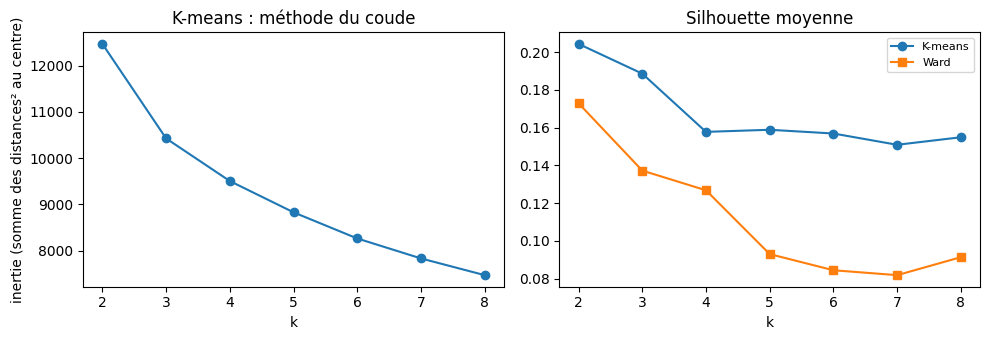

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(choix_k.index, choix_k["inertie K-means"], marker="o")
axes[0].set_title("K-means : méthode du coude")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertie (somme des distances² au centre)")
axes[1].plot(choix_k.index, choix_k["silhouette K-means"], marker="o", label="K-means")
axes[1].plot(choix_k.index, choix_k["silhouette Ward"], marker="s", label="Ward")
axes[1].set_title("Silhouette moyenne")
axes[1].set_xlabel("k")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "clustering_choix_k.png", dpi=150)
plt.show()

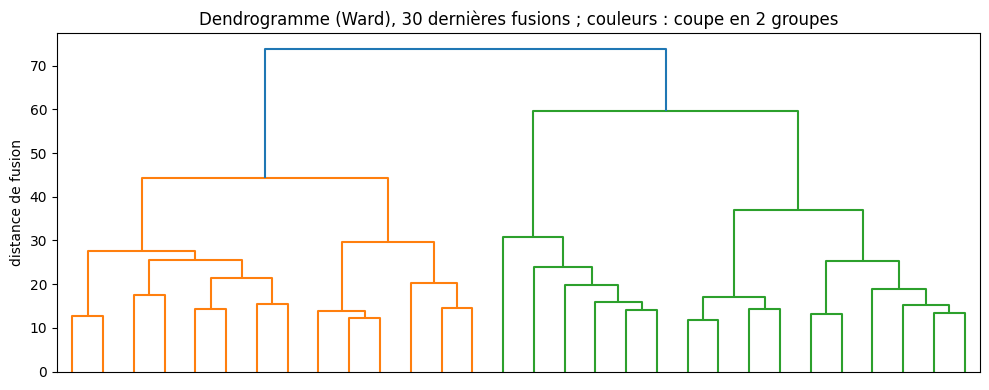

Distances des 8 dernières fusions : [25.5 27.7 29.7 30.9 36.9 44.3 59.6 73.8]


In [18]:
from scipy.cluster.hierarchy import dendrogram, linkage

liens = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(liens, truncate_mode="lastp", p=30, no_labels=True, ax=ax, color_threshold=liens[-(k_ward - 1), 2])
ax.set_title(f"Dendrogramme (Ward), 30 dernières fusions ; couleurs : coupe en {k_ward} groupes")
ax.set_ylabel("distance de fusion")
fig.tight_layout()
fig.savefig(FIGURES / "clustering_dendrogramme.png", dpi=150)
plt.show()
print("Distances des 8 dernières fusions :", np.round(liens[-8:, 2], 1))

In [19]:
bic = pd.Series({n: GaussianMixture(n_components=n, covariance_type="full", random_state=GRAINE).fit(X).bic(X)
                 for n in range(1, 9)}, name="BIC")
n_gmm = int(bic.idxmin())
print(f"Mélange gaussien : {n_gmm} composantes (BIC minimal)")
bic.round(0).to_frame().T

Mélange gaussien : 7 composantes (BIC minimal)


,1,2,3,4,5,6,7,8
BIC,40810.0,38829.0,26888.0,26737.0,26909.0,17506.0,17289.0,26505.0


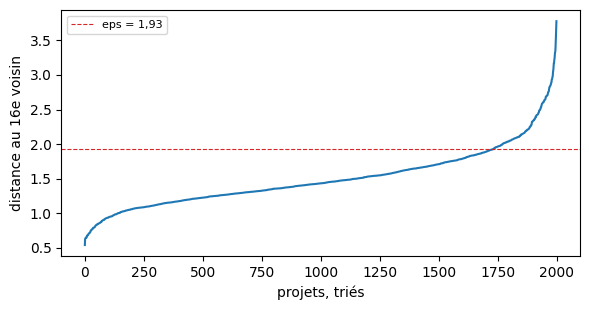

eps retenu : 1.93


In [20]:
MIN_SAMPLES = 2 * len(VARIABLES)
distances, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)
k_dist = np.sort(distances[:, -1])
# Coude : point le plus éloigné de la droite qui joint le premier et le dernier point de la courbe
x_norm = np.linspace(0, 1, len(k_dist))
y_norm = (k_dist - k_dist[0]) / (k_dist[-1] - k_dist[0])
indice_coude = int(np.argmax(x_norm - y_norm))
eps = float(k_dist[indice_coude])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(k_dist)
ax.axhline(eps, color="tab:red", ls="--", lw=0.8, label=f"eps = {eps:.2f}".replace(".", ","))
ax.set_xlabel("projets, triés")
ax.set_ylabel(f"distance au {MIN_SAMPLES}e voisin")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "clustering_dbscan_eps.png", dpi=150)
plt.show()
print(f"eps retenu : {eps:.2f}")

### Tableau comparatif

Les mesures sont calculées sur les projets classés. Pour DBSCAN, on retire le bruit : sa silhouette n'est donc pas tout à fait comparable aux autres.

- **Silhouette** (plus haut = mieux, maximum 1).
- **Davies-Bouldin** (plus bas = mieux) : rapport entre la dispersion dans les groupes et la distance entre groupes.
- **Calinski-Harabasz** (plus haut = mieux) : rapport entre la dispersion entre groupes et la dispersion dans les groupes.

In [21]:
etiquettes = {
    f"K-means (k={k_kmeans})": KMeans(n_clusters=k_kmeans, n_init=10, random_state=GRAINE).fit_predict(X),
    f"Ward (k={k_ward})": AgglomerativeClustering(n_clusters=k_ward, linkage="ward").fit_predict(X),
    f"DBSCAN (eps={eps:.2f})": DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X),
    f"Mélange gaussien ({n_gmm})": GaussianMixture(n_components=n_gmm, covariance_type="full",
                                                    random_state=GRAINE).fit_predict(X),
}
lignes = []
for nom, lab in etiquettes.items():
    classes = lab != -1
    n_groupes = len(set(lab[classes]))
    tailles = pd.Series(lab[classes]).value_counts()
    mesurable = n_groupes >= 2
    lignes.append({
        "méthode": nom, "groupes": n_groupes,
        "bruit (%)": round(100 * (~classes).mean(), 1),
        "plus petit groupe (%)": round(100 * tailles.min() / len(lab), 1) if n_groupes else np.nan,
        "silhouette": silhouette_score(X[classes], lab[classes]) if mesurable else np.nan,
        "Davies-Bouldin": davies_bouldin_score(X[classes], lab[classes]) if mesurable else np.nan,
        "Calinski-Harabasz": calinski_harabasz_score(X[classes], lab[classes]) if mesurable else np.nan,
    })
comparaison = pd.DataFrame(lignes).set_index("méthode")
comparaison["écartée"] = ((comparaison["plus petit groupe (%)"] < 5) | (comparaison["bruit (%)"] > 20)
                          | (comparaison["groupes"] < 2))
comparaison.round(3).to_csv(RACINE / "reports" / "role2" / "clustering_comparaison.csv")
comparaison.round(3)

,groupes,bruit (%),plus petit groupe (%),silhouette,Davies-Bouldin,Calinski-Harabasz,écartée
méthode,,,,,,,
K-means (k=2),2,0.0,47.2,0.204,1.801,565.745,False
Ward (k=2),2,0.0,39.7,0.173,2.078,410.241,False
DBSCAN (eps=1.93),1,4.2,95.8,NaN,NaN,NaN,True
Mélange gaussien (7),7,0.0,0.4,0.052,2.965,119.674,True


In [22]:
# Les méthodes trouvent-elles les mêmes groupes ? Indice de Rand ajusté (1 = identiques, 0 = hasard)
noms = list(etiquettes)
pd.DataFrame([[adjusted_rand_score(etiquettes[a], etiquettes[b]) for b in noms] for a in noms],
             index=noms, columns=noms).round(2)

,K-means (k=2),Ward (k=2),DBSCAN (eps=1.93),Mélange gaussien (7)
K-means (k=2),1.00,0.29,0.01,0.24
Ward (k=2),0.29,1.00,0.03,0.35
DBSCAN (eps=1.93),0.01,0.03,1.00,0.05
Mélange gaussien (7),0.24,0.35,0.05,1.00


In [23]:
retenues = comparaison[~comparaison["écartée"]]
methode_retenue = retenues["silhouette"].idxmax() if len(retenues) else comparaison["silhouette"].idxmax()
groupes = pd.Series(etiquettes[methode_retenue], index=X.index, name="groupe")
print("Groupes décrits :", methode_retenue)

Groupes décrits : K-means (k=2)


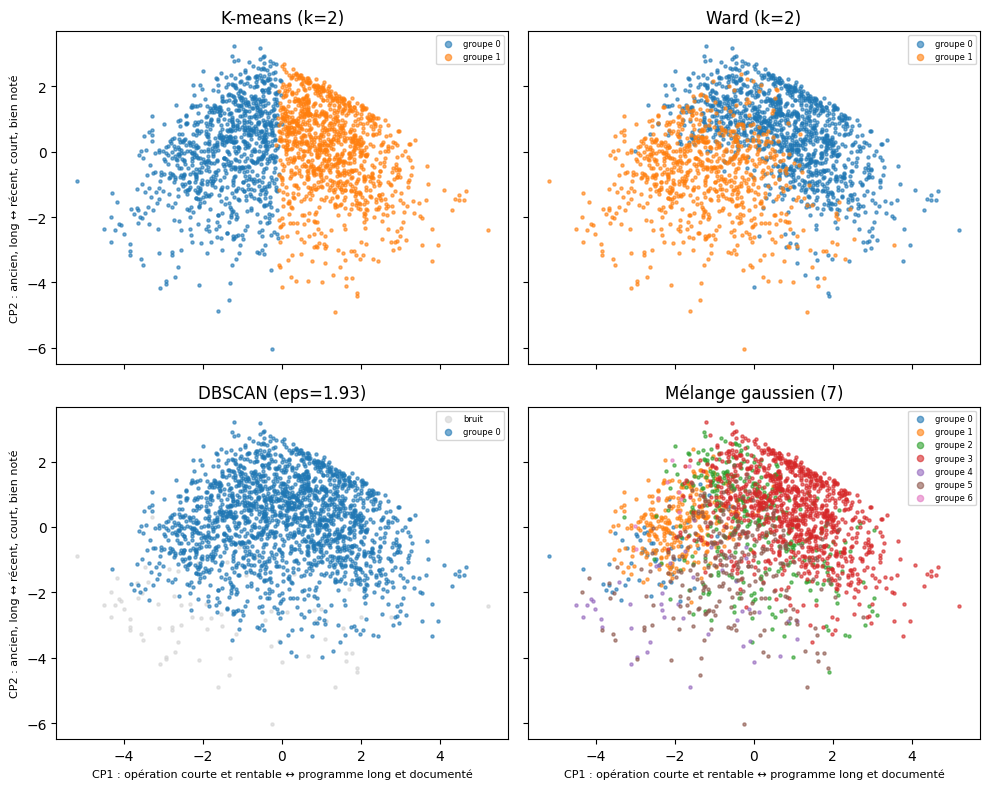

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, (nom, lab) in zip(axes.ravel(), etiquettes.items()):
    for g in sorted(set(lab)):
        masque = lab == g
        ax.scatter(coordonnees.loc[masque, "CP1"], coordonnees.loc[masque, "CP2"], s=5, alpha=0.6,
                   c="lightgrey" if g == -1 else None, label="bruit" if g == -1 else f"groupe {g}")
    ax.set_title(nom)
    ax.legend(fontsize=6, markerscale=2)
for ax in axes[1]:
    ax.set_xlabel("CP1 : opération courte et rentable ↔ programme long et documenté", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("CP2 : ancien, long ↔ récent, court, bien noté", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "clustering_plan_acp.png", dpi=150)
plt.show()

### Description des groupes retenus

Moyennes des variables d'origine (non standardisées) par groupe, puis le secteur le plus fréquent, la part de projets en cours et la part de projets signalés par `detect_anomalies`. Ces derniers sont repérés par notre propre détecteur, pas par la vérité terrain.

In [25]:
from src.mcda import detect_anomalies

signale = detect_anomalies(donnees)["anomalie"].to_numpy()
description = donnees.assign(groupe=groupes.to_numpy(), signale=signale).groupby("groupe").agg(
    projets=("id_projet", "size"),
    cout_median=("cout_total", "median"),
    duree=("duree_mois", "mean"),
    annee=("annee_approbation", "mean"),
    rentabilite_predite=("rentabilite_predite", "mean"),
    proba_risque=("proba_risque", "mean"),
    impact=("impact_env_social", "mean"),
    alignement=("alignement_strategique", "mean"),
    faisabilite=("faisabilite", "mean"),
    en_cours_pct=("statut", lambda s: 100 * (s == "en_cours").mean()),
    signales_pct=("signale", lambda s: 100 * s.mean()),
    secteur_principal=("secteur", lambda s: f"{s.mode()[0]} ({100 * (s == s.mode()[0]).mean():.0f} %)"),
)
description.to_csv(RACINE / "reports" / "role2" / "clustering_groupes.csv")
description.round(2)

,projets,cout_median,duree,annee,rentabilite_predite,proba_risque,impact,alignement,faisabilite,en_cours_pct,signales_pct,secteur_principal
groupe,,,,,,,,,,,,
0,943,28.0,47.23,2011.28,9.38,0.1,3.44,3.57,3.48,16.44,6.89,Gouvernance (23 %)
1,1057,100.0,83.85,2011.28,7.15,0.4,4.39,4.30,4.67,32.64,3.31,Gouvernance (16 %)


In [26]:
# Écart de chaque groupe à la moyenne générale, en écarts-types (lecture rapide du profil)
X.groupby(groupes.to_numpy()).mean().round(2)

,log_cout,duree_mois,annee_approbation,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite
0,-0.37,-0.62,-0.0,0.53,-0.58,-0.48,-0.45,-0.63
1,0.33,0.55,0.0,-0.48,0.52,0.43,0.40,0.56


### Bilan du clustering

**Il n'y a pas de groupes naturels bien séparés dans ces projets.** Les quatre méthodes le disent, chacune à sa façon :

| Méthode | Réglage (règle fixée à l'avance) | Groupes | Silhouette | Verdict |
|---|---|---|---|---|
| K-means | k = 2 (meilleure silhouette de 2 à 8) | 2 (47 % / 53 %) | **0,20** | retenue, structure faible |
| Hiérarchique (Ward) | k = 2 | 2 (40 % / 60 %) | 0,17 | structure faible |
| DBSCAN | eps = 1,93, 16 voisins | 1 seul groupe et 4 % de bruit | — | écartée : pas de partition |
| Mélange gaussien | 7 composantes (BIC minimal) | 7, dont une de 9 projets | 0,05 | écartée : groupe de 0,4 % |

- **Silhouettes basses** : une silhouette de 0,20 au mieux veut dire que beaucoup de projets sont presque à égale distance de deux groupes. La silhouette baisse quand k augmente, et l'inertie de K-means descend régulièrement, sans coude net.
- **DBSCAN** trouve un seul nuage dense : les 2 000 projets forment une masse continue. Les 4 % de « bruit » sont les projets en bordure, surtout en bas à gauche du plan de l'ACP (anciens, courts, mal notés).
- **Le mélange gaussien est piégé par les notes entières.** Ses composantes collent aux valeurs exactes d'une note : la composante 3 ne contient que des projets notés 5 en faisabilité, la composante 5 que des projets notés 3. Une cloche de Gauss posée sur une valeur unique a une variance quasi nulle, donc une vraisemblance énorme, ce qui fait chuter le BIC artificiellement (17 289 avec 7 composantes contre 26 737 avec 4). C'est une limite connue : le modèle suppose des variables continues.
- **Les méthodes ne s'accordent pas** : l'indice de Rand ajusté entre K-means et Ward n'est que de 0,29. K-means coupe le nuage verticalement (le long de CP1), Ward en diagonale.

**Les deux groupes retenus (K-means, k = 2)** coupent en deux le premier axe de l'ACP :

- **Groupe 0, « petites opérations courtes et rentables »** (943 projets) : coût médian de 28 M$, environ 47 mois, rentabilité prédite de 9,4 %, risque prédit faible (0,10), notes moyennes (3,4 à 3,6) ; 16 % de projets en cours, 6,9 % signalés par `detect_anomalies`.
- **Groupe 1, « grands programmes longs, risqués et bien notés »** (1 057 projets) : coût médian de 100 M$, environ 84 mois, rentabilité prédite de 7,2 %, risque prédit de 0,40, notes élevées (4,3 à 4,7) ; 33 % de projets en cours, 3,3 % signalés.

Les deux groupes ont la même année moyenne (2011). La gouvernance est le secteur le plus fréquent dans les deux, mais ne domine aucun groupe (23 % et 16 %) : **le secteur n'explique pas les groupes**.

**À retenir pour le rapport** : le clustering confirme l'ACP. Les projets s'étalent le long d'un continuum (des opérations courtes et rentables aux grands programmes longs), sans familles distinctes. Les deux groupes de K-means sont une **coupe commode** de ce continuum, pas des types de projets naturels. C'est un résultat en soi : il n'y a pas de segment de projets à traiter à part dans le classement.
